In [1]:
import os

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn_extra.cluster import KMedoids
from sklearn.decomposition import PCA

from cluster_weather_years.functions import build_df, plot_clim_per_cluster

from cluster_weather_years.constants import BASE_OUTPUT

In [2]:
# Build NL dataframe
NUM_CLUSTERS = 5
df_daily, df_nl_rolling = build_df()

# 1. Compute mean and standard deviation per year w.r.t. climatology

In [3]:
clim_means = df_daily.loc[
    :, [c for c in df_daily.columns if c != "Hydrological_year"]
].mean(axis=0)

yearly_means = df_daily.groupby(
    [pd.Grouper(level="model"), df_daily["Hydrological_year"]]
).agg("mean")

# normalize it by the climatological mean, and convert into percentage
yearly_mean_anom_norm = (yearly_means - clim_means) * 100 / clim_means

clim_stds = df_daily.loc[
    :, [c for c in df_daily.columns if c != "Hydrological_year"]
].std(axis=0)
yearly_stds = df_daily.groupby(
    [pd.Grouper(level="model"), df_daily["Hydrological_year"]]
).agg("std")

# normalize it by the climatological std, and convert into percentage
yearly_std_anom_norm = (yearly_stds - clim_stds) * 100 / clim_stds

In [5]:
yearly_means["NL_ON"].mean(), yearly_means["NL_ON"].std()

(0.26121933445548084, 0.029720616904504407)

In [6]:
yearly_mean_anom_std_scaled = (yearly_means - clim_means) / yearly_means.std()


(-50.0, 50.0)

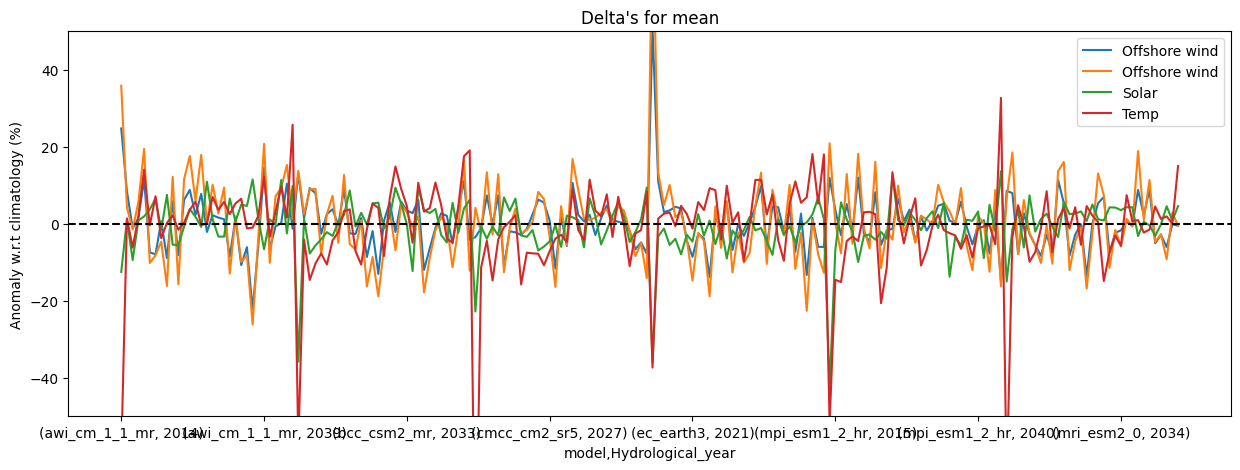

In [7]:
# NOTE: CDD is out of bounds for these plotting ylims.
plt.figure(figsize=(15, 5))
yearly_mean_anom_norm["NL_OFF"].plot(label="Offshore wind")
yearly_mean_anom_norm["NL_ON"].plot(label="Offshore wind")
yearly_mean_anom_norm["NL_SOLAR"].plot(label="Solar")
yearly_mean_anom_norm["NL_TEMP"].plot(label="Temp")
plt.axhline(y=0, c="k", linestyle="--")
# yearly_mean_anom_norm["CDD"].plot(label="CDD")
# yearly_mean_anom_norm["HDD"].plot(label="HDD")

plt.legend()
plt.ylabel("Anomaly w.r.t climatology (%)")
plt.title("Delta's for mean")
plt.ylim(-50, 50)

(-50.0, 50.0)

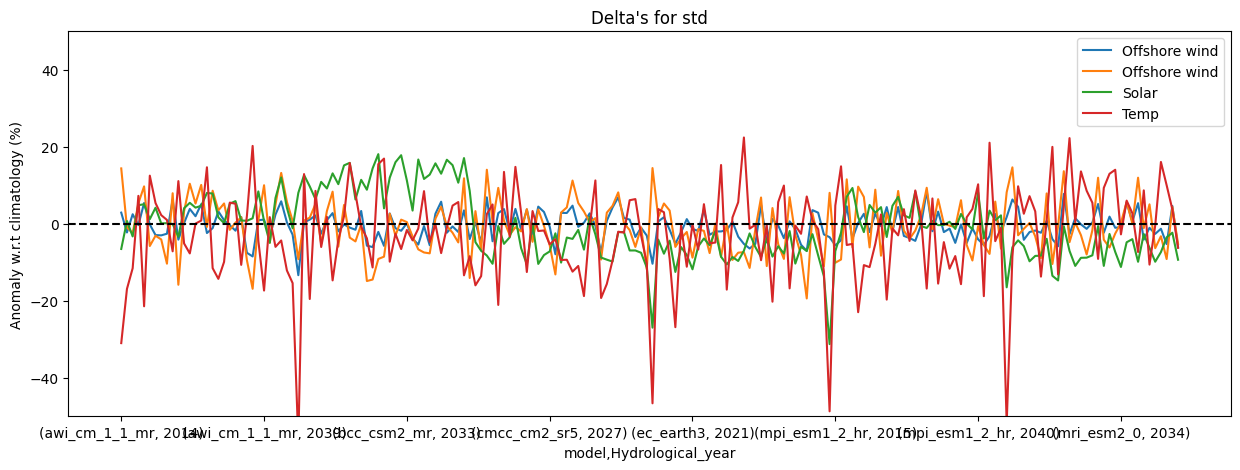

In [8]:
plt.figure(figsize=(15, 5))

yearly_std_anom_norm["NL_OFF"].plot(label="Offshore wind")
yearly_std_anom_norm["NL_ON"].plot(label="Offshore wind")
yearly_std_anom_norm["NL_SOLAR"].plot(label="Solar")
yearly_std_anom_norm["NL_TEMP"].plot(label="Temp")
plt.axhline(y=0, c="k", linestyle="--")

# yearly_std_anom_norm["CDD"].plot(label="CDD")
# yearly_std_anom_norm["HDD"].plot(label="HDD")


plt.legend(loc="upper right")
plt.ylabel("Anomaly w.r.t climatology (%)")
plt.title("Delta's for std")
plt.ylim(-50, 50)

# 2. Perform K-Medoids clustering

In [9]:
# standardize the data to mean = 0, std = 1
# TODO: Add HDD and CDD instead of TEMP
df_standardize = df_daily[["NL_OFF", "NL_ON", "NL_SOLAR", "NL_TEMP"]]

scaler = StandardScaler()
df_standardized = pd.DataFrame(
    scaler.fit_transform(df_standardize),
    columns=df_standardize.columns,
    index=df_daily.index,
)

In [10]:
def p95_day(s: pd.Series) -> float:
    """Return the 95th percentile of a Series."""
    return s.quantile(0.95)


def p5_day(s: pd.Series) -> float:
    """Return the 5th percentile of a Series."""
    return s.quantile(0.05)


def p95_week(s: pd.Series) -> float:
    """Return the 95th percentile week of a Series."""
    return s.rolling(window=7).mean().quantile(0.95)


def p5_week(s: pd.Series) -> float:
    """Return the 5th percentile week of a Series."""
    return s.rolling(window=7).mean().quantile(0.05)


year = pd.Index(
    df_nl_rolling.index.get_level_values("Date").year,
    name="year",
)

# yearly_stats = df_standardized.groupby([pd.Grouper(level="model"), year]).agg(
#     ["mean", "var", p95_day, p5_day, p95_week, p5_week]
# )

yearly_stats = df_standardized.groupby([pd.Grouper(level="model"), year]).agg(
    ["mean", "var"]
)

yearly_stats.columns = [f"{col}_{stat}" for col, stat in yearly_stats.columns]

# scale the year‑level feature matrix
X = StandardScaler().fit_transform(yearly_stats)

In [11]:
# perform K-Medoids clustering

kmed = KMedoids(n_clusters=NUM_CLUSTERS).fit(X)
yearly_stats["cluster_med"] = kmed.labels_

pca = PCA(n_components=2, random_state=0)
X_pca = pca.fit_transform(X)  # (n_years, 2)
centers_pca = pca.transform(kmed.cluster_centers_)  # (k, 2)

# 3. Visualize clusters, using PCA-projection

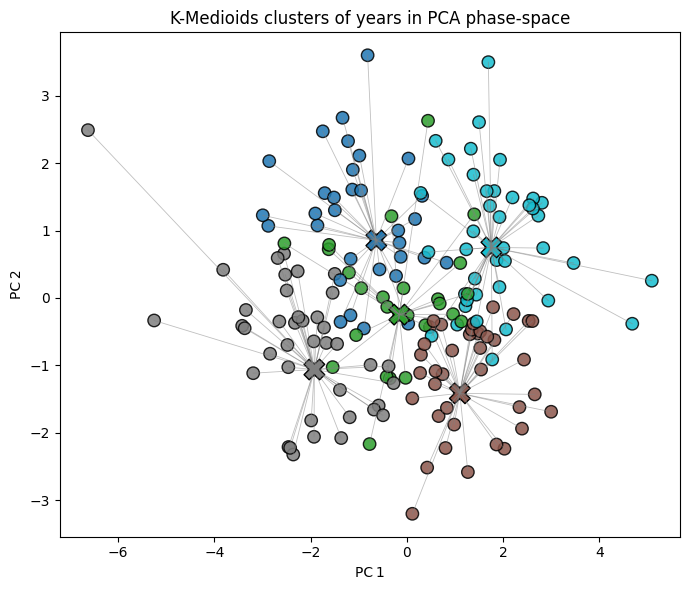

In [12]:
fig, ax = plt.subplots(figsize=(7, 6))

# years as coloured dots
pts = ax.scatter(
    X_pca[:, 0],
    X_pca[:, 1],
    c=kmed.labels_,
    cmap="tab10",
    s=80,
    alpha=0.85,
    edgecolor="k",
)

# lines to centroids (distance visualisation)
for i, (x, y) in enumerate(X_pca):
    cx, cy = centers_pca[kmed.labels_[i]]
    ax.plot([x, cx], [y, cy], lw=0.6, color="grey", alpha=0.5)

# centroids as large X‑markers
ax.scatter(
    centers_pca[:, 0],
    centers_pca[:, 1],
    marker="X",
    c=range(len(centers_pca)),
    cmap="tab10",
    s=220,
    edgecolor="k",
)

ax.set_xlabel("PC 1")
ax.set_ylabel("PC 2")
ax.set_title("K-Medioids clusters of years in PCA phase‑space")
plt.tight_layout()
plt.show()

In [13]:
loadings = pd.DataFrame(
    pca.components_.T,  # shape (n_feats, n_components)
    index=yearly_stats.columns[:-1],  # drop 'cluster'
    columns=["PC1", "PC2"],
).round(3)

print("PCA loadings (coefficients):")
print(loadings)
print("\nExplained variance ratio:", pca.explained_variance_ratio_.round(3))

PCA loadings (coefficients):
                 PC1    PC2
NL_OFF_mean    0.464 -0.132
NL_OFF_var     0.363  0.269
NL_ON_mean     0.504 -0.047
NL_ON_var      0.481  0.177
NL_SOLAR_mean -0.152  0.646
NL_SOLAR_var   0.015  0.468
NL_TEMP_mean   0.109  0.465
NL_TEMP_var   -0.364  0.158

Explained variance ratio: [0.434 0.208]


# 4. Analyze centroids

In [ ]:
indices = kmed.medoid_indices_
centroid_years = yearly_mean_anom_norm.iloc[indices].copy()
centroid_years["count"] = (
    yearly_stats["cluster_med"].value_counts(sort=False).sort_index().values
)
centroid_years["cluster_id"] = range(5)
centroid_years_to_save = centroid_years.reset_index().set_index("cluster_id")

fname_centroids = os.path.join(BASE_OUTPUT, "centroids/centroid_years_cf.csv")
centroid_years_to_save.to_csv(fname_centroids)
centroid_years_to_save

,model,Hydrological_year,NL_OFF,DE_OFF,BE_OFF,FR_OFF,NL_ON,DE_ON,BE_ON,FR_ON,...,BE_SOLAR,FR_SOLAR,NL_TEMP,DE_TEMP,BE_TEMP,FR_TEMP,Calendar_year,CDD,HDD,count
cluster_id,,,,,,,,,,,,,,,,,,,,,
0,cmcc_cm2_sr5,2032,2.364400,0.982494,9.631725,9.226215,8.789939,2.420672,13.447256,11.139447,...,1.700775,-1.142774,-1.576035,-1.360832,-1.443232,0.001601,0.135315,-100.000000,-3.158930,33
1,mpi_esm1_2_hr,2033,4.745323,6.886597,9.710285,9.863916,10.162563,12.161334,13.927745,9.319882,...,-1.896655,2.296014,2.407054,4.999301,1.534562,2.034399,0.184588,-100.000000,-20.701872,26
2,cmcc_cm2_sr5,2038,0.956728,3.602092,-2.802127,-2.285261,0.053216,-7.973126,-8.408694,-5.746581,...,1.495447,2.119815,-3.386028,-6.721689,-4.082966,-1.780522,0.430954,-100.000000,-0.418802,39
3,cmcc_cm2_sr5,2040,0.171974,-1.465052,5.670265,11.066612,3.431737,2.325219,10.170835,15.670877,...,2.250194,1.521558,-0.324030,0.902424,2.859382,4.839537,0.529500,18.034794,0.175466,41
4,cmcc_cm2_sr5,2037,4.825035,5.473393,2.804838,-5.921347,3.801449,-7.856574,-2.850414,-7.148901,...,-1.950265,0.235842,7.697983,6.864816,4.623029,1.927869,0.381681,-48.503750,-25.038366,41


In [15]:
yearly_mean_anom_std_scaled.iloc[indices]

NL_OFF    DE_OFF    BE_OFF    FR_OFF  \
model         Hydrological_year                                           
cmcc_cm2_sr5  2032               0.317510  0.124881  1.098603  1.074506   
mpi_esm1_2_hr 2033               0.637240  0.875329  1.107564  1.148775   
cmcc_cm2_sr5  2038               0.128477  0.457848 -0.319613 -0.266147   
              2040               0.023094 -0.186217  0.646756  1.288843   
              2037               0.647944  0.695702  0.319922 -0.689614   

                                    NL_ON     DE_ON     BE_ON     FR_ON  \
model         Hydrological_year                                           
cmcc_cm2_sr5  2032               0.768053  0.216781  1.216135  1.167413   
mpi_esm1_2_hr 2033               0.887991  1.089098  1.259589  0.976723   
cmcc_cm2_sr5  2038               0.004650 -0.714026 -0.760461 -0.602241   
              2040               0.299861  0.208233  0.919824  1.642306   
              2037               0.332166 -0.703589 -0.257784 -0.749204   

                                 NL_SOLAR  DE_SOLAR  BE_SOLAR  FR_SOLAR  \
model         Hydrological_year                                           
cmcc_cm2_sr5  2032               0.135978  0.242730  0.235553 -0.210144   
mpi_esm1_2_hr 2033              -0.150216  0.160001 -0.262682  0.422213   
cmcc_cm2_sr5  2038               0.303687  0.316697  0.207116  0.389812   
              2040               0.265502 -0.167090  0.311646  0.279799   
              2037              -0.237096 -0.138076 -0.270107  0.043369   

                                  NL_TEMP   DE_TEMP   BE_TEMP   FR_TEMP  \
model         Hydrological_year                                           
cmcc_cm2_sr5  2032              -0.113168 -0.079258 -0.104147  0.000130   
mpi_esm1_2_hr 2033               0.172839  0.291172  0.110738  0.164817   
cmcc_cm2_sr5  2038              -0.243134 -0.391488 -0.294637 -0.144250   
              2040              -0.023267  0.052559  0.206340  0.392077   
              2037               0.552755  0.399824  0.333609  0.156187   

                                 Calendar_year       CDD       HDD  
model         Hydrological_year                                     
cmcc_cm2_sr5  2032                    0.308039 -0.382741 -0.093839  
mpi_esm1_2_hr 2033                    0.420208 -0.382741 -0.614967  
cmcc_cm2_sr5  2038                    0.981052 -0.382741 -0.012441  
              2040                    1.205390  0.069027  0.005212  
              2037                    0.868884 -0.185644 -0.743786

In [16]:
clim_means

NL_OFF              0.446613
DE_OFF              0.424797
BE_OFF              0.395682
FR_OFF              0.418211
NL_ON               0.259695
DE_ON               0.226945
BE_ON               0.267884
FR_ON               0.240012
NL_SOLAR            0.110097
DE_SOLAR            0.113047
BE_SOLAR            0.112313
FR_SOLAR            0.129699
NL_TEMP            11.161806
DE_TEMP            10.163768
BE_TEMP            11.043928
FR_TEMP            12.272788
Calendar_year    2029.500365
CDD                 0.004285
HDD                 3.261573
dtype: float64

In [ ]:
plot_clim_per_cluster(
    df_nl_rolling, yearly_stats, centroid_years, "NL_OFF", num_clusters=NUM_CLUSTERS
)

IndexError: boolean index did not match indexed array along dimension 0; dimension is 5406 but corresponding boolean dimension is 180

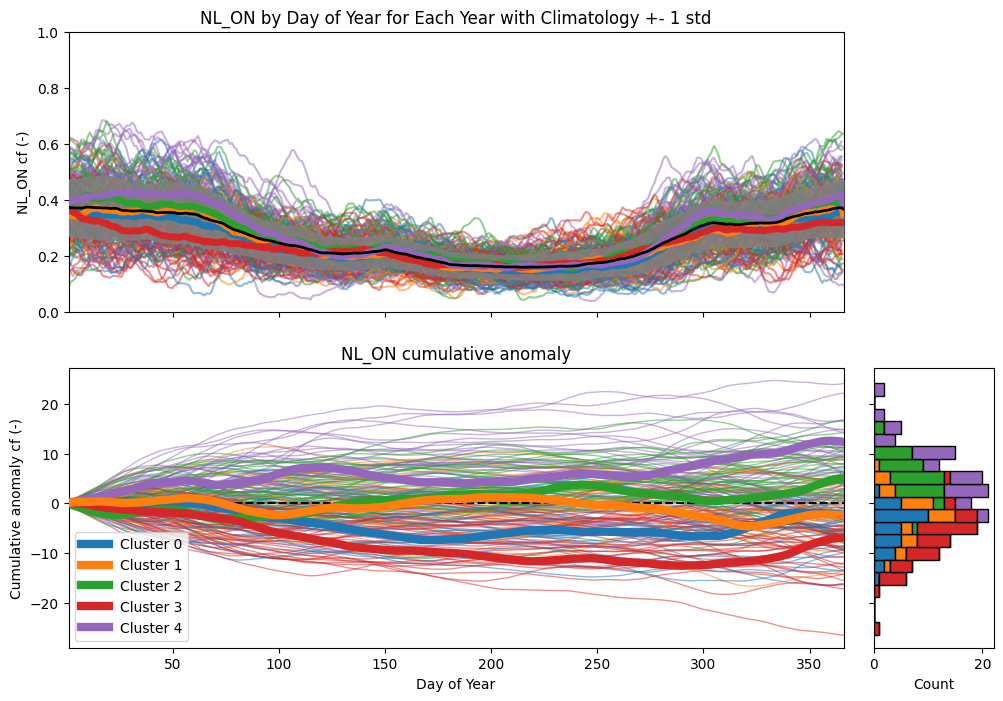

In [14]:
plot_clim_per_cluster(df_nl_rolling, yearly_stats, centroid_years, "NL_ON")

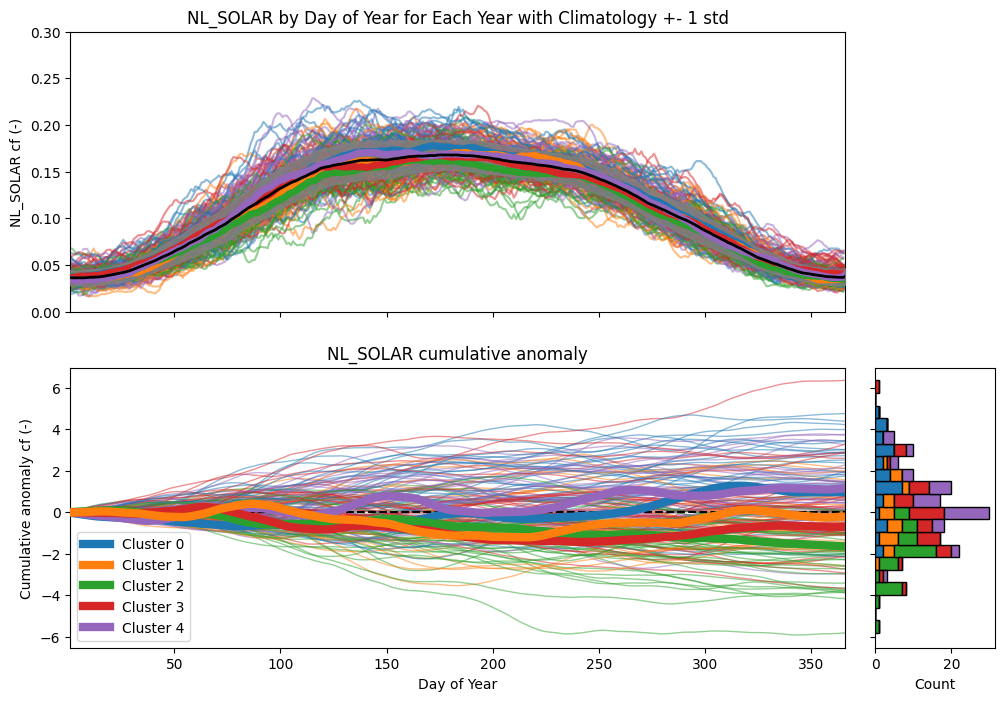

In [15]:
plot_clim_per_cluster(df_nl_rolling, yearly_stats, centroid_years, "NL_SOLAR")

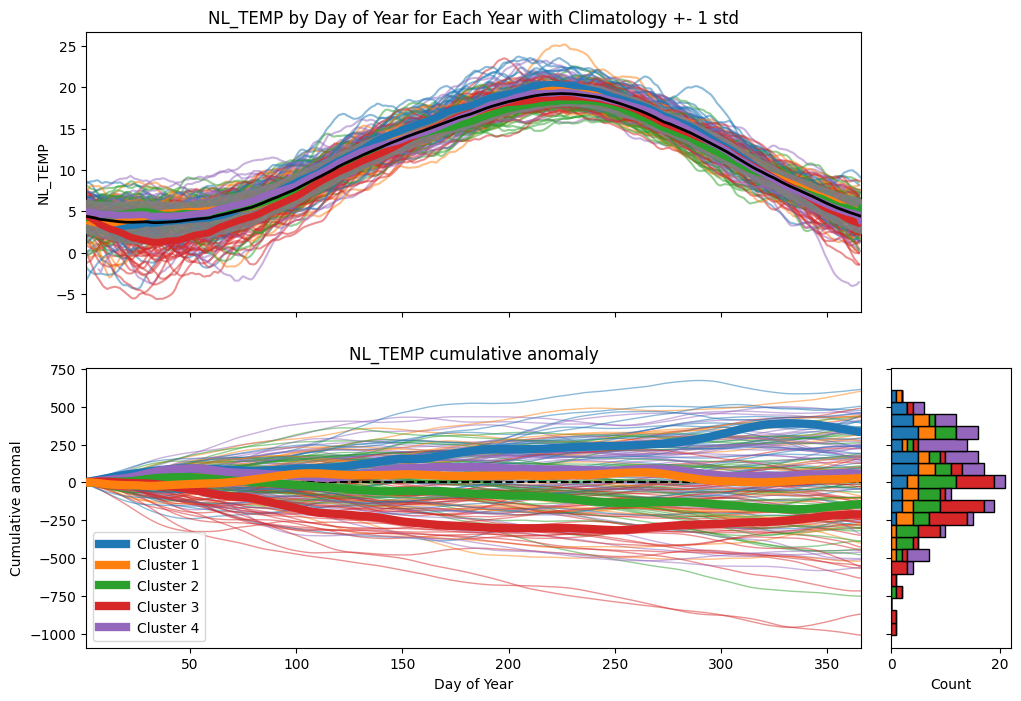

In [16]:
plot_clim_per_cluster(df_nl_rolling, yearly_stats, centroid_years, "NL_TEMP")